# Tutorial Notebook for IT_TF github repository

This notebook is WIP. Documentation will be added shortly. For now, we only go through regenerating the main figures in the paper

## Information Decay 
#### Starting from the ground up, we will generate 2 column MI/PI motifOrganisms encoding 1 bit of Total Information . We then bombard these motifs with mutations and compare how quickly their information decays. 

First, let's generate the motifPopulation with PI organisms. All scripts in this repo are setup to work with parameters specified through json files. As such, we specify the parameters for the population before running the script which generates the desired motif Population

##### Note: In any/all scripts, PI from the paper is referred to as IC in the code

In [1]:
import json

In [2]:
#Writing proper parameters for IC population to JSON file
ICjsonfile_fig1 = {
    "inputFile": None, #Loads in pre-generated motifPopulation or starts from scratch
	"Number_Organisms": 100,
	"Number_BindingSites": 128,
	"Length_BindingSites": 2,
	"GC_cont": 0.50, #Biases the mutation towards certain letters if not set to 0.50
	"Mutation_Rate": 0.01, #Expected rate of mutations per generation (mean of Poisson distribution)
	"MI_mode": 1, #Overlapping pairs (1) or non-overlapping pairs (2) for computing MI
	"ReadInFiles": None, #Paths to fasta files for initilaizing motifModels
	"Target_TI_Column": 0.5, #Target_TI_Column * Length_BindingSites equals desired bits of information
	"Prop_IC": 1, #Proportion of Target_TI_Column * Length_BindingSites that should be IC/PI
	"ConstrictMode": "IC", #Parameter of the fitness function. Determines whether to solely select for PI/IC, MI, or both
	"Eucledian_Thres": 0.05, #Max distance allowed for any organism from goal information before stopping simulation
    "restartPopulation": None, #If int specified, restarts population after # of generations. May help if getting stuck in local optima
	"populationOutputFile": "./Notebook/Populations/Figure_1/ICpop_fig1.json"
}  

with open("./src/settings_fitMotifPop.json", "w") as f:
    json.dump(ICjsonfile_fig1, f, indent = 3)



In [3]:
import src.fitMotifPopulation

version 0.1.8


In [4]:
#We then generate the ICmotifPop
src.fitMotifPopulation.main() 

Number Organisms below threshold: 0
Generation num: 100
Number Organisms below threshold: 0
Generation num: 200
Number Organisms below threshold: 0
Generation num: 300
Number Organisms below threshold: 3
Generation num: 400
Number Organisms below threshold: 55
Generation num: 500
Number Organisms below threshold: 97
Generation num: 600


We then run the information decay experiment outlined in the paper, where we bombard our generated motifs with mutations in the absence of any selection pressure to see how fast the information decays

In [5]:
ICjsonfile_fig1_decay = {
    "Population_File":"./Notebook/Populations/Figure_1/ICpop_fig1.json",
	"NumGenerationTerminate":1000,
	"lossOutputCSV": "./Notebook/Results/Figure_1/informationDecay_ICpop_fig1.json"	
}

with open("./src/settings_informationDecay.json", "w") as f:
    json.dump(ICjsonfile_fig1_decay, f, indent = 3)

In [6]:
import src.informationDecay

In [7]:
#We then run the Information Decay experiment
src.informationDecay.main()

Let's do the same with MI motifs. The only `parameters` changed are `Prop_IC` and `ConstrictMode`

In [8]:
#Writing proper parameters for MI population to JSON file
MIjsonfile_fig1 = {
    "inputFile": None,
	"Number_Organisms": 100,
	"Number_BindingSites": 128,
	"Length_BindingSites": 2,
	"GC_cont": 0.50,
	"Mutation_Rate": 0.01,
	"MI_mode": 1,
	"ReadInFiles": None,
	"Target_TI_Column": 0.5,
	"Prop_IC": 0,
	"ConstrictMode": "MI",
	"Eucledian_Thres": 0.05,
    "restartPopulation": None,
	"populationOutputFile": "./Notebook/Populations/Figure_1/MIpop_fig1.json"
}  

with open("./src/settings_fitMotifPop.json", "w") as f:
    json.dump(MIjsonfile_fig1, f, indent = 3)


In [9]:
#We then generate the ICmotifPop
src.fitMotifPopulation.main() 

Number Organisms below threshold: 0
Generation num: 100
Number Organisms below threshold: 0
Generation num: 200
Number Organisms below threshold: 0
Generation num: 300
Number Organisms below threshold: 2
Generation num: 400
Number Organisms below threshold: 13
Generation num: 500
Number Organisms below threshold: 52
Generation num: 600
Number Organisms below threshold: 77
Generation num: 700
Number Organisms below threshold: 95
Generation num: 800
Number Organisms below threshold: 99
Generation num: 900
Number Organisms below threshold: 99
Generation num: 1000


In [10]:
MIjsonfile_fig1_decay = {
    "Population_File":"./Notebook/Populations/Figure_1/MIpop_fig1.json",
	"NumGenerationTerminate":1000,
	"lossOutputCSV": "./Notebook/Results/Figure_1/informationDecay_MIpop_fig1.json"		
}

with open("./src/settings_informationDecay.json", "w") as f:
    json.dump(MIjsonfile_fig1_decay, f, indent = 3)

In [11]:
#We then run the Information Decay experiment
src.informationDecay.main()

Visualizing the results. In figureFunctions.py, all the graphs from the paper and supplementary document can be regenerated given the results have already been generated

In [12]:
import src.figureFunctions


Figure(640x480)


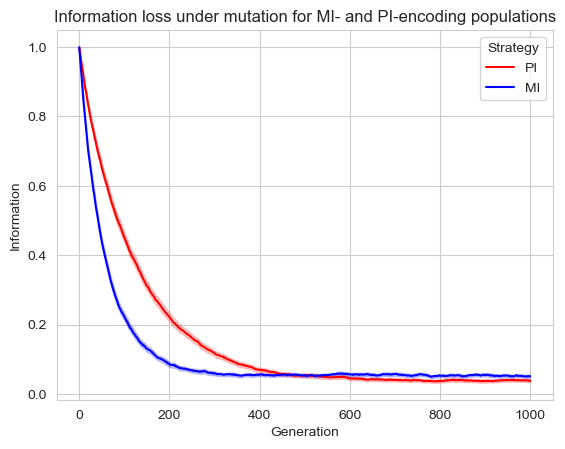

In [13]:
#Note: For the figure functions, order that we pass in the files is very important
print(src.figureFunctions.Figure1(["./Notebook/Results/Figure_1/informationDecay_ICpop_fig1.json", 
                                   "./Notebook/Results/Figure_1/informationDecay_MIpop_fig1.json"])) #Figure1

##### The above figure seems to indicate PI motifs maintain more of their Information after mutation than MI motifs. What about motifs between 100% IC and 100% MI? We proceed to generate motifs that encode their Information somewhere between 100% IC and 100% MI and compare their mutational resillience 

In [14]:
#Defines encoding strategies. 0% IC 100% MI, 25% IC 75% MI, ...
propInformation = [0,0.25,0.50, 0.75,1]

#Repeats the process completed above for each strata between 100% IC and 100% MI in propInformation
for percentageIC in propInformation:

    #Generates json file and outputs it
    mixedjsonfile_fig1 = {
    "inputFile": None,
	"Number_Organisms": 100,
	"Number_BindingSites": 128,
	"Length_BindingSites": 2,
	"GC_cont": 0.50,
	"Mutation_Rate": 0.01,
	"MI_mode": 1,
	"ReadInFiles": None,
	"Target_TI_Column": 0.5,
	"Prop_IC": percentageIC,
	"ConstrictMode": "",
	"Eucledian_Thres": 0.05,
    "restartPopulation": None,
	"populationOutputFile": f"./Notebook/Populations/SuppFigure_1/mixedpop_{percentageIC}_fig1.json"
    
    }  
    with open("./src/settings_fitMotifPop.json", "w") as f:
        json.dump(mixedjsonfile_fig1, f, indent = 3)

    #Generates population
    src.fitMotifPopulation.main() 

    #Runs information decay experiment
    mixedjsonfile_fig1_decay = {
    "Population_File":f"./Notebook/Populations/SuppFigure_1/mixedpop_{percentageIC}_fig1.json",
	"NumGenerationTerminate":1000,
	"lossOutputCSV": f"./Notebook/Results/SuppFigure_1/informationDecay_mixedpop_{percentageIC}_fig1.json"	
    }

    with open("./src/settings_informationDecay.json", "w") as f:
        json.dump(mixedjsonfile_fig1_decay, f, indent = 3)

    print(f"Done with {percentageIC}IC motifPopulation!") 
        
    src.informationDecay.main()

Number Organisms below threshold: 0
Generation num: 100
Number Organisms below threshold: 0
Generation num: 200
Number Organisms below threshold: 0
Generation num: 300
Number Organisms below threshold: 1
Generation num: 400
Number Organisms below threshold: 18
Generation num: 500
Number Organisms below threshold: 47
Generation num: 600
Number Organisms below threshold: 76
Generation num: 700
Number Organisms below threshold: 93
Generation num: 800
Number Organisms below threshold: 97
Generation num: 900
Number Organisms below threshold: 99
Generation num: 1000
Done with 0IC motifPopulation!
Number Organisms below threshold: 0
Generation num: 100
Number Organisms below threshold: 0
Generation num: 200
Number Organisms below threshold: 0
Generation num: 300
Number Organisms below threshold: 2
Generation num: 400
Number Organisms below threshold: 15
Generation num: 500
Number Organisms below threshold: 57
Generation num: 600
Number Organisms below threshold: 81
Generation num: 700
Number 

Figure(640x480)


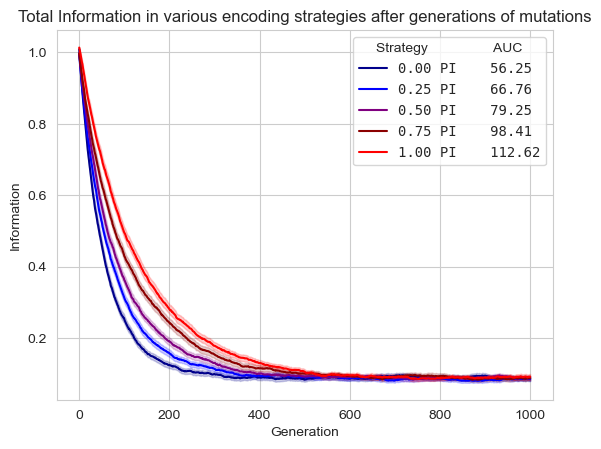

In [15]:
#Visualizing the results!
print(src.figureFunctions.SupplementaryFigure1([f"./Notebook/Results/SuppFigure_1/informationDecay_mixedpop_{percentageIC}_fig1.json" for percentageIC in propInformation]))

##### The above figure seems to suggest that motifs that encode most of their information through PI are better positioned to maintain Information than motifs that trend more towards MI. We can see a clear improvement in mutational resilience going from MI to PI. 

##### A follow-up question. Transcription factors (TF) bind to sites that follow a certain motif pattern. Problems arise when these binding sites get mutated and start diverging from the pattern recognized by the TF. We can represent the original pattern as a probability frequency distribution and the mutated sites as another distribution. How does the divergence of IC binding sites from the motif after mutations compared to MI binding sites? To measure divergence, we employ Jennsen-Shannon Divergence

Figure(640x480)


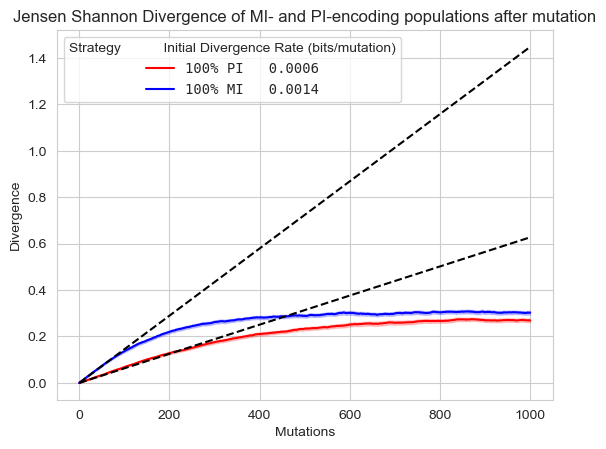

In [16]:
#Reusing the IC/MI informationDecay files we already generated, the JSD figure is visualized below
print(src.figureFunctions.SupplementaryFigure2(["./Notebook/Results/Figure_1/informationDecay_ICpop_fig1.json", 
                                   "./Notebook/Results/Figure_1/informationDecay_MIpop_fig1.json"]))

##### Examining whether these mutational resillience properties remain true of IC and MI motifs as we vary Information Density by altering `Target_TI_Column`

You could generate the populations yourself by setting `Target_TI_Column` to the following values: 0.25, 0.5, 0.75, and 1 bit for `Prop_IC` = 1 and `ConstrictMode` = IC as well for `Prop_IC`=0 and `ConstrictMode` = MI. This has already been done for you and saved to the repo. Here, we simply load in the pre-generated population 

In [17]:
#Defines different TI values for 2bp motif. 
TIlist = [0.5,1,1.5,2] 

#Repeats for MI and IC
for strategy in ["IC","MI"]:
    
    #Repeats the process completed above for each information density value in the list above
    for TI in TIlist:
        
        #Runs information decay experiment
        jsonfile_fig2_decay = {
        "Population_File":f"./Notebook/Populations/Figure_2/motifPop_{TI}bit{strategy}_2col.json",
    	"NumGenerationTerminate":1000,
    	"lossOutputCSV": f"./Notebook/Results/Figure_2/informationDecay_{TI}bit{strategy}.csv"	
        }
    
        with open("./src/settings_informationDecay.json", "w") as f:
            json.dump(jsonfile_fig2_decay, f, indent = 3)
                
        src.informationDecay.main()
    
    print(f"Done with {strategy} motifPopulations!") 


Done with IC motifPopulations!
Done with MI motifPopulations!


Figure(640x480)


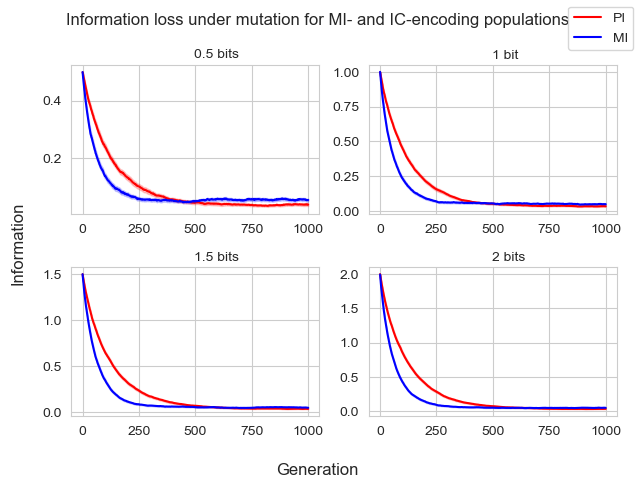

In [18]:
fig2_fileList = []
for TI in TIlist:
    fig2_fileList.append([f"./Notebook/Results/Figure_2/informationDecay_{TI}bitIC.csv",
                          f"./Notebook/Results/Figure_2/informationDecay_{TI}bitMI.csv" ])
fig2_fileList
print(src.figureFunctions.Figure2(fig2_fileList))

##### Finally, we generate more realistically sized motifs and repeat the information decay experiments 

You can generate these PI/MI MotifPopulations with `target_TI_Column`: 0.5 and `Length_BindingSites` = 12 selecting for PI/MI by altering `Prop_IC` to 1/0 and `ConstrictMode` to IC/MI. The generated populations are already saved and loaded in here:

In [19]:
for strategy in ["IC", "MI"]:
    jsonfile_fig3_decay = {
        "Population_File":f"./Notebook/Populations/Figure_3/motifPop_6bit{strategy}_12col.json",
    	"NumGenerationTerminate":3000,
    	"lossOutputCSV": f"./Notebook/Results/Figure_3/informationDecay_{strategy}bit.csv"	
    }

    with open("./src/settings_informationDecay.json", "w") as f:
        json.dump(jsonfile_fig3_decay, f, indent = 3)
    
    #We then run the Information Decay experiment
    src.informationDecay.main()

Figure(640x480)


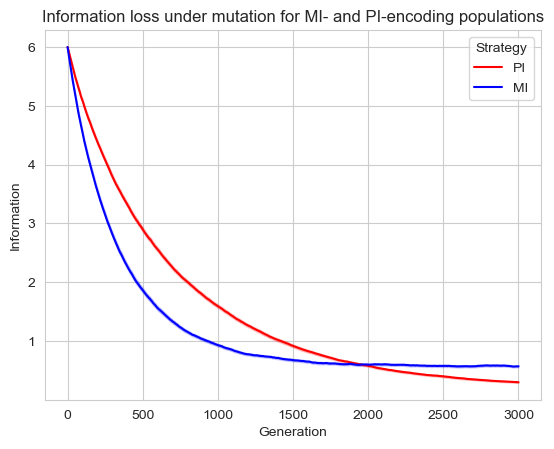

In [21]:
print(src.figureFunctions.Figure3(["./Notebook/Results/Figure_3/informationDecay_ICbit.csv", "./Notebook/Results/Figure_3/informationDecay_MIbit.csv"])) 

# Genome Search
We now further complicate our model by introducing a genome to explore interesting properties about IC/MI motifs. Specifically, we insert our motifs into a genome, introduce mutations to the genome, and measure how quickly the classification ability of binding sites from non-binding sites degrade. We measure classification ability through AUPRC and train a Kulakovsky model on the binding sites before mutation to classify binding sites and non-binding sites.  

First, we load in our fitted motifs (Code to generate motifs commented below). We then run the genome search by putting the motifs in genomes and measuring AUPRC after mutation.
We'll be visualizing AUPRC curves with different motif length

In [22]:
#Defines different length values
motifLengths = [10,12,14,16]
fileList_fig4 = []
for L in motifLengths:
    fileList_fig4.append([f"motifPop_{L/2}bitIC_{L}col.json", f"motifPop_{L/2}bitMI_{L}col.json"])


In [30]:
"""
#Defines different length values
motifLengths = [10,12,14,16]

#Repeats for MI and IC
for strategy in ["IC","MI"]:
    propIC = 1 if strategy == "IC" else 0
    #Repeats the process completed above for each motifLength above
    for L in motifLengths:
    
        #Generates json file and outputs it
        jsonfile_fig4 = {
        "inputFile": None,
    	"Number_Organisms": 100,
    	"Number_BindingSites": 128,
    	"Length_BindingSites": L,
    	"GC_cont": 0.50,
    	"Mutation_Rate": 0.01,
    	"MI_mode": 1,
    	"ReadInFiles": None,
    	"Target_TI_Column": 0.5,
    	"Prop_IC": propIC,
    	"ConstrictMode": strategy,
    	"Eucledian_Thres": 0.05,
        "restartPopulation":None,
    	"populationOutputFile": f"./Notebook/Populations/Figure_4/motifpop_{int(L/2)}bit{strategy}_{int(L)}col.json"
        }  
        
        with open("./src/settings_fitMotifPop.json", "w") as f:
            json.dump(jsonfile_fig4, f, indent = 3)
    
        #Generates population
        src.fitMotifPopulation.main() 
    
    
    print(f"Done with {strategy} motifPopulations!") 
"""

'\n#Defines different length values\nmotifLengths = [10,12,14,16]\n\n#Repeats for MI and IC\nfor strategy in ["IC","MI"]:\n    propIC = 1 if strategy == "IC" else 0\n    #Repeats the process completed above for each motifLength above\n    for L in motifLengths:\n    \n        #Generates json file and outputs it\n        jsonfile_fig4 = {\n        "inputFile": None,\n    \t"Number_Organisms": 100,\n    \t"Number_BindingSites": 128,\n    \t"Length_BindingSites": L,\n    \t"GC_cont": 0.50,\n    \t"Mutation_Rate": 0.01,\n    \t"MI_mode": 1,\n    \t"ReadInFiles": None,\n    \t"Target_TI_Column": 0.5,\n    \t"Prop_IC": propIC,\n    \t"ConstrictMode": strategy,\n    \t"Eucledian_Thres": 0.05,\n        "restartPopulation":None,\n    \t"populationOutputFile": f"./Notebook/Figure_4/motifpop_{propIC}bit{strategy}_{L}col.json"\n        }  \n        \n        with open("./src/settings_fitMotifPop.json", "w") as f:\n            json.dump(jsonfile_fig4, f, indent = 3)\n    \n        #Generates popula

In [31]:
import src.genomeSearch

Note: This will take a *long* time if run in a jupyter notebook. As such, the results have already been generated by running the script and saved to Notebook/Results/Figure_4

In [36]:
motifLengths = [10,12,14,16]

#Repeats for MI and IC
for strategy in ["IC","MI"]:
    propIC = 1 if strategy == "IC" else 0
    #Repeats the process completed above for each motifLength above
    for L in motifLengths:
        inputMotifFilePath = f"./Notebook/Populations/Figure_4/motifpop_{int(L/2)}bit{strategy}_{int(L)}col.json"
        
        jsonfile_fig4 = {
        	"Population_File": inputMotifFilePath,
            "genomeLength": 8192, #Appropriate genome length according to Schneider's equation given 6 bits of information and 128 binding sites
            "NumGenerationTerminate": 10000,
            "lossOutputCSV": f"/Notebook/Results/Figure_4/genomeSearch_{L/2}bit{strategy}_{L}col.csv"
        }  

        with open("./src/settings_GenomeExperiment.json", "w") as f:
            json.dump(jsonfile_fig4, f, indent = 3)

        #Runs genomeSearch
        src.genomeSearch.main()
    
        

Completed one organism


KeyboardInterrupt: 

In [ ]:
src.figureFunctions.Figure4()

# Coevolutionary Simulation
To further explore fitness properties of PI/MI TRNs, we use a coevolutionary simulation to evolve recognizers/binding sites along with the rest of the genome. We first tackle the question of whether MI or PI TRNs would propagate in a population as a property of the mutational resillience of PI TRNs (competition experiment). Given this mutational robustness property, we next ask whether TRNs would naturally move towards encoding their information through PI while solely selecting for classification performance (vector field). Please note that all of the below work was done with the assistance of a high performance computing cluster; however, the generated results are saved in the repo

Example of generating an organism using the simulation:

Competition Experiment visualization

Vector Field